# Métricas extra sobre la ablación de bloques — effective rank y CKA (2026-08-30)

Extiende `notebooks/22082026_ablation/ablation.ipynb` y `notebooks/23082026_block_cutoff/block_cutoff.ipynb`
con métricas geométricas (bloque A del capítulo, *feature study* — punto **A.1** de `CLAUDE.md`)
para el ViT de 4 bloques entrenado en CIFAR-10.

**Notebook parametrizable.** Se elige el modelo en la *única* celda de configuración de abajo
(`MODEL_NAME`). Todo el resto corre igual sea cual sea el checkpoint. La idea es ejecutarlo
una vez con el modelo estándar y otra con el interpretable; cada corrida guarda sus propios
archivos, con `MODEL_NAME` en el nombre, sin pisarse.

Métricas (todas sobre el **mismo sample de referencia n=1000** que usó la ablación previa, para que
los números sean comparables entre corridas):

1. **Effective rank de fc1 (MLP) por bloque** — sobre los pesos de la primera lineal del MLP
   (`block.mlp.dense_1`, la que expande `hidden_size -> intermediate_size`).
2. **Effective rank del clasificador final** — sobre `model.classifier.weight` (mapea al espacio de 10 clases).
3. **Effective rank del attention output por bloque** — sobre activaciones: salida de la proyección
   final de atención (tras concatenar cabezas, **antes** del residual add — mismo punto de captura que
   `forward_with_head_ablated` en `ablation.ipynb`), aplanadas sobre `samples * seq_len`.
4. **Matriz CKA 4x4** (linear CKA, Kornblith et al. 2019) entre los attention outputs de los 4 bloques.

Effective rank = `exp(H(sigma_norm))` (Roy & Vetterli 2007), reutilizando `modules.effective_rank.effective_rank`.

Cada tarea **calcula y grafica en su propia celda**, con el eje llevado hasta el máximo teórico de esa
métrica (`min(dims)` para los effective ranks, `1.0` para el CKA), para que las gráficas de las dos
corridas (`MODEL_NAME` distinto) se puedan poner lado a lado directamente. Toda gráfica se guarda como
PNG en `OUTPUT_DIR` con `MODEL_TAG` en el nombre, además de mostrarse inline.

## 0. Configuración — única celda que cambia entre corridas

In [32]:
# ======================================================================
#  CONFIGURACIÓN  —  lo único que se cambia entre la corrida estándar
#  y la interpretable.
# ======================================================================
interpretable = False                       # o False
MODEL_NAME = f"vit-with-10-epochs{'-interpretable' if interpretable else ''}"
N_REF      = 1000                           # sample de referencia (mismo que ablation.ipynb)
# ======================================================================

import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision

# Misma convención que el resto de notebooks/: vive 2 niveles bajo la raíz del proyecto.
project_root = Path.cwd().resolve().parents[1]
sys.path.append(str(project_root))

from modules.model import ViTForClassfication
from modules.datasets import CIFAR10Dataset
from modules.effective_rank import effective_rank
from modules.cka import linear_cka

torch.manual_seed(0)

# --- Resolver la carpeta del checkpoint --------------------------------
# Acepta el nombre corto ("vit-with-15-epochs") o el nombre completo de la
# carpeta ("vit-with-15-epochs-CIFAR10").
experiments_root = project_root / "experimentation" / "experiments"
_candidates = [experiments_root / MODEL_NAME, experiments_root / f"{MODEL_NAME}-CIFAR10"]
exp_dir = next((c for c in _candidates if c.exists()), None)
if exp_dir is None:
    raise FileNotFoundError(
        "No encontré la carpeta del experimento. Probé: "
        + ", ".join(str(c) for c in _candidates)
    )

# Etiqueta usada en TODOS los archivos de salida — distingue las dos corridas
# (contiene "interpretable" cuando corresponde).
MODEL_TAG = re.sub(r"[^0-9A-Za-z._-]+", "-", MODEL_NAME)
IS_INTERPRETABLE = "interpretable" in MODEL_NAME.lower()

# Carpeta de salida dentro de la carpeta de experimentos existente del proyecto.
# (cambiar esta línea si se prefiere otra ubicación; los nombres de archivo ya
#  llevan MODEL_TAG, así que las dos corridas conviven sin pisarse).
OUTPUT_DIR = experiments_root / "30082026_block_extra_metrics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, stem):
    """Guarda la figura como PNG en OUTPUT_DIR con MODEL_TAG en el nombre."""
    path = OUTPUT_DIR / f"{stem}_{MODEL_TAG}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"guardado: {path.relative_to(project_root)}")
    return path


print(f"MODEL_NAME : {MODEL_NAME}  ({'interpretable' if IS_INTERPRETABLE else 'baseline / estándar'})")
print(f"exp_dir    : {exp_dir.relative_to(project_root)}")
print(f"OUTPUT_DIR : {OUTPUT_DIR.relative_to(project_root)}")
print(f"MODEL_TAG  : {MODEL_TAG}")
print(f"N_REF      : {N_REF}")

MODEL_NAME : vit-with-10-epochs  (baseline / estándar)
exp_dir    : experimentation/experiments/vit-with-10-epochs-CIFAR10
OUTPUT_DIR : experimentation/experiments/30082026_block_extra_metrics
MODEL_TAG  : vit-with-10-epochs
N_REF      : 1000


## 1. Cargar el modelo

Mismo patrón que `ablation.ipynb` / `block_cutoff.ipynb`: `config.json` + `metrics.json` + `model_final.pt`,
con `map_location="cpu"` (los checkpoints se guardaron desde MPS). El `assert` sobre `use_faster_attention`
protege el resto del notebook, que asume cabezas separadas (`block.attention.heads`) y `block.mlp.dense_1`.

In [33]:
with open(exp_dir / "config.json") as f:
    config = json.load(f)
with open(exp_dir / "metrics.json") as f:
    metrics = json.load(f)

assert not config["use_faster_attention"], (
    "Este notebook asume atención no-fusionada (block.attention.heads / block.mlp.dense_1); "
    "con use_faster_attention=True habría que adaptar los puntos de captura."
)

model = ViTForClassfication(config)
state_dict = torch.load(exp_dir / "model_final.pt", map_location="cpu")
model.load_state_dict(state_dict)
model.eval()

n_blocks          = len(model.encoder.blocks)
n_heads           = config["num_attention_heads"]
hidden_size       = config["hidden_size"]
intermediate_size = config["intermediate_size"]
num_classes       = config["num_classes"]
block_labels      = [f"block {i + 1}" for i in range(n_blocks)]

print(f"Checkpoint {MODEL_NAME}: accuracy de entrenamiento = {metrics['accuracy']:.4f}")
print(f"bloques={n_blocks} | cabezas/bloque={n_heads} | hidden={hidden_size} "
      f"| intermediate={intermediate_size} | clases={num_classes}")

Checkpoint vit-with-10-epochs: accuracy de entrenamiento = 0.5613
bloques=4 | cabezas/bloque=4 | hidden=48 | intermediate=192 | clases=10


## 2. Sample de referencia (n = 1000)

Exactamente el mismo lote que `ablation.ipynb`: primeras `N_REF` imágenes del test de CIFAR-10
(`get_samples_from_indices(range(N_REF), set="test")`), apuntando a `experimentation/data` para no
re-descargar. Así el effective rank de las activaciones (Tarea 3) y la matriz CKA (Tarea 4) son
comparables entre esta corrida y las de la ablación.

In [34]:
dataset = CIFAR10Dataset()
dataset.testset = torchvision.datasets.CIFAR10(
    root=str(project_root / "experimentation" / "data"),
    train=False,
    download=True,
    transform=dataset.test_transform,
)
classes = dataset.classes

ref_images, ref_labels = dataset.get_samples_from_indices(range(N_REF), device="cpu", set="test")
print(f"Sample de referencia: {tuple(ref_images.shape)}  (índices 0..{N_REF - 1} del test) — mismo que ablation.ipynb")

Sample de referencia: (1000, 3, 32, 32)  (índices 0..999 del test) — mismo que ablation.ipynb


## Tarea 1 — Effective rank de los pesos de fc1 (MLP) por bloque

`fc1` / `linear1` = la primera lineal del MLP, la que **expande** la dimensión antes de la activación.
En `modules/model.py` es `block.mlp.dense_1`; su `weight` tiene shape `(intermediate_size, hidden_size)`
= `(192, 48)`. Effective rank vía SVD: valores singulares -> normalizar como distribución (dividir por
su suma) -> `exp(entropía)` (Roy & Vetterli 2007).

**Máximo teórico:** `min(192, 48) = 48` (la línea punteada y el tope del eje `y` de la gráfica).

block 1: fc1 weight (192, 48)  ->  effective_rank = 39.0089
block 2: fc1 weight (192, 48)  ->  effective_rank = 33.1410
block 3: fc1 weight (192, 48)  ->  effective_rank = 36.8138
block 4: fc1 weight (192, 48)  ->  effective_rank = 38.0915
guardado: experimentation/experiments/30082026_block_extra_metrics/effrank_mlp_fc1_by_block_vit-with-10-epochs.png


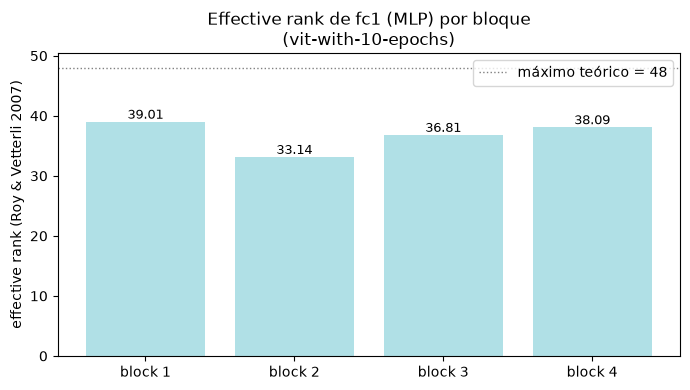

In [35]:
erank_mlp = []
for i, block in enumerate(model.encoder.blocks):
    W = block.mlp.dense_1.weight.detach()          # (intermediate_size, hidden_size) = (192, 48)
    er = effective_rank(W).item()
    erank_mlp.append(er)
    print(f"block {i + 1}: fc1 weight {tuple(W.shape)}  ->  effective_rank = {er:.4f}")

max_erank_mlp = min(intermediate_size, hidden_size)   # 48

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(block_labels, erank_mlp, color="powderblue")
for rect, v in zip(bars, erank_mlp):
    ax.text(rect.get_x() + rect.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
ax.axhline(max_erank_mlp, color="gray", linestyle=":", linewidth=1,
           label=f"máximo teórico = {max_erank_mlp}")
ax.set_ylabel("effective rank (Roy & Vetterli 2007)")
ax.set_title(f"Effective rank de fc1 (MLP) por bloque\n({MODEL_NAME})")
ax.set_ylim(0, max_erank_mlp * 1.05)
ax.legend()
plt.tight_layout()
save_fig(fig, "effrank_mlp_fc1_by_block")
plt.show()

## Tarea 2 — Effective rank del clasificador final

`model.classifier` es la lineal final `hidden_size -> num_classes`; su `weight` tiene shape `(10, 48)`.
Mismo método que la Tarea 1.

**Máximo teórico:** `min(10, 48) = 10`.

classifier weight (10, 48)  ->  effective_rank = 8.6222  (máximo teórico = 10)
guardado: experimentation/experiments/30082026_block_extra_metrics/effrank_classifier_vit-with-10-epochs.png


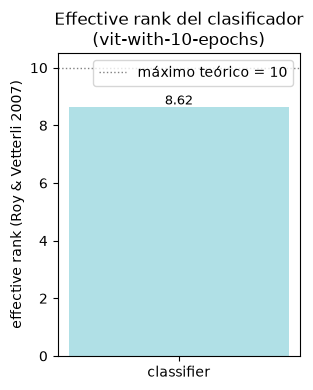

In [36]:
W_clf = model.classifier.weight.detach()           # (num_classes, hidden_size) = (10, 48)
erank_classifier = effective_rank(W_clf).item()
max_erank_classifier = min(num_classes, hidden_size)   # 10
print(f"classifier weight {tuple(W_clf.shape)}  ->  effective_rank = {erank_classifier:.4f}  "
      f"(máximo teórico = {max_erank_classifier})")

fig, ax = plt.subplots(figsize=(3.2, 4))
bar = ax.bar(["classifier"], [erank_classifier], color="powderblue", width=0.5)
ax.text(0, erank_classifier, f"{erank_classifier:.2f}", ha="center", va="bottom", fontsize=9)
ax.axhline(max_erank_classifier, color="gray", linestyle=":", linewidth=1,
           label=f"máximo teórico = {max_erank_classifier}")
ax.set_ylabel("effective rank (Roy & Vetterli 2007)")
ax.set_title(f"Effective rank del clasificador\n({MODEL_NAME})")
ax.set_ylim(0, max_erank_classifier * 1.05)
ax.legend()
plt.tight_layout()
save_fig(fig, "effrank_classifier")
plt.show()

## Tarea 3 — Effective rank del attention output por bloque (activaciones)

Punto de captura: **la salida de la proyección final de atención**, es decir el primer elemento que
devuelve `MultiHeadAttention.forward` (`attention_output`), que ya es `output_projection(concat(cabezas))`
tras el `output_dropout` y **antes** del residual add. Es exactamente el mismo punto que usa
`forward_with_head_ablated` en `notebooks/22082026_ablation/ablation.ipynb`, así que los números son
comparables con ese notebook.

Se captura con un `forward_hook` sobre cada `block.attention` durante un único forward sobre el sample
de referencia. Cada activación tiene shape `(N_REF, seq_len, hidden_size)` con `seq_len = num_patches + 1 = 65`.
Para el SVD se aplana sobre `samples * seq_len` -> matriz `(N_REF * 65, 48)`.

**Máximo teórico:** `min(N_REF * seq_len, hidden_size) = 48`.

block 1: activaciones (1000, 65, 48) -> aplanado (65000, 48) -> effective_rank = 14.5417
block 2: activaciones (1000, 65, 48) -> aplanado (65000, 48) -> effective_rank = 17.1730
block 3: activaciones (1000, 65, 48) -> aplanado (65000, 48) -> effective_rank = 16.3699
block 4: activaciones (1000, 65, 48) -> aplanado (65000, 48) -> effective_rank = 14.1211
guardado: experimentation/experiments/30082026_block_extra_metrics/effrank_attn_output_by_block_vit-with-10-epochs.png


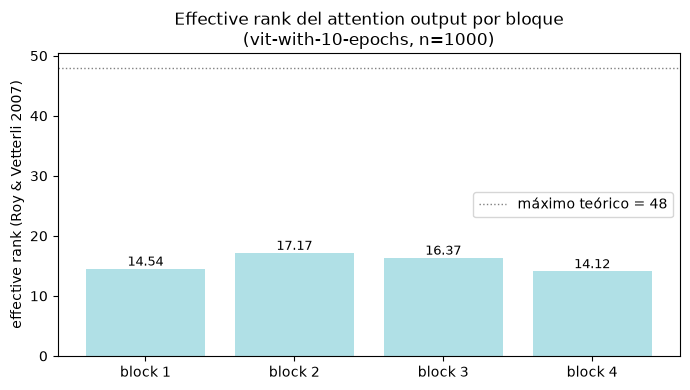

In [37]:
attn_out_acts = {}

def _make_hook(idx):
    def hook(module, inputs, output):
        # MultiHeadAttention.forward -> (attention_output, attention_probs);
        # attention_output = output_projection(concat(cabezas)) tras output_dropout,
        # ANTES del residual add. Mismo punto de captura que ablation.ipynb.
        attn_out_acts[idx] = output[0].detach()
    return hook

handles = [
    block.attention.register_forward_hook(_make_hook(i))
    for i, block in enumerate(model.encoder.blocks)
]
try:
    with torch.no_grad():
        _ = model(ref_images, output_attentions=False)
finally:
    for h in handles:
        h.remove()

erank_attn_out = []
attn_out_flat  = []   # se reutiliza en la Tarea 4 (CKA)
for i in range(n_blocks):
    act  = attn_out_acts[i]                              # (N_REF, seq_len, hidden_size)
    flat = act.reshape(-1, act.shape[-1]).contiguous()   # (N_REF * seq_len, hidden_size)
    attn_out_flat.append(flat)
    er = effective_rank(flat).item()
    erank_attn_out.append(er)
    print(f"block {i + 1}: activaciones {tuple(act.shape)} -> aplanado {tuple(flat.shape)} "
          f"-> effective_rank = {er:.4f}")

max_erank_attn = min(attn_out_flat[0].shape[0], hidden_size)   # 48

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(block_labels, erank_attn_out, color="powderblue")
for rect, v in zip(bars, erank_attn_out):
    ax.text(rect.get_x() + rect.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
ax.axhline(max_erank_attn, color="gray", linestyle=":", linewidth=1,
           label=f"máximo teórico = {max_erank_attn}")
ax.set_ylabel("effective rank (Roy & Vetterli 2007)")
ax.set_title(f"Effective rank del attention output por bloque\n({MODEL_NAME}, n={N_REF})")
ax.set_ylim(0, max_erank_attn * 1.05)
ax.legend()
plt.tight_layout()
save_fig(fig, "effrank_attn_output_by_block")
plt.show()

## Tarea 4 — Matriz de similitud CKA entre attention outputs de bloques

`linear_cka` (Kornblith et al. 2019, `modules/cka.py`) sobre las matrices aplanadas de la Tarea 3,
para los 6 pares `(1,2) (1,3) (1,4) (2,3) (2,4) (3,4)`. Matriz `4x4` simétrica con diagonal = 1.

**Máximo teórico:** `1.0` (idénticas salvo rotación/escala isotrópica). El heatmap usa escala de
color fija `vmin=0, vmax=1`, así que los mapas de las dos corridas se comparan directamente.

CKA(block 1, block 2) = 0.3454
CKA(block 1, block 3) = 0.1264
CKA(block 1, block 4) = 0.2716
CKA(block 2, block 3) = 0.1238
CKA(block 2, block 4) = 0.2997
CKA(block 3, block 4) = 0.1747
guardado: experimentation/experiments/30082026_block_extra_metrics/cka_attn_output_blocks_vit-with-10-epochs.csv
guardado: experimentation/experiments/30082026_block_extra_metrics/cka_attn_output_blocks_heatmap_vit-with-10-epochs.png


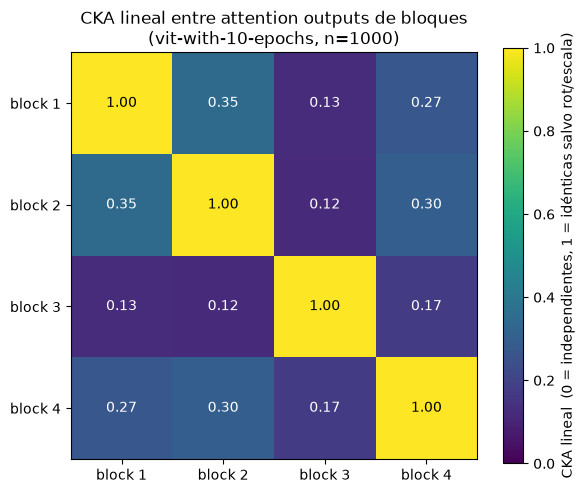

In [38]:
cka_matrix = np.eye(n_blocks)
for a in range(n_blocks):
    for b in range(a + 1, n_blocks):
        val = linear_cka(attn_out_flat[a].float(), attn_out_flat[b].float()).item()
        cka_matrix[a, b] = val
        cka_matrix[b, a] = val
        print(f"CKA(block {a + 1}, block {b + 1}) = {val:.4f}")

# CSV de la matriz, para trazabilidad en la tesis.
cka_df = pd.DataFrame(cka_matrix,
                      index=[f"block_{i + 1}" for i in range(n_blocks)],
                      columns=[f"block_{i + 1}" for i in range(n_blocks)])
cka_csv_path = OUTPUT_DIR / f"cka_attn_output_blocks_{MODEL_TAG}.csv"
cka_df.to_csv(cka_csv_path)
print(f"guardado: {cka_csv_path.relative_to(project_root)}")

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cka_matrix, cmap="viridis", vmin=0.0, vmax=1.0)   # máximo teórico = 1.0
ax.set_xticks(range(n_blocks)); ax.set_xticklabels(block_labels)
ax.set_yticks(range(n_blocks)); ax.set_yticklabels(block_labels)
for a in range(n_blocks):
    for b in range(n_blocks):
        ax.text(b, a, f"{cka_matrix[a, b]:.2f}", ha="center", va="center",
                color="white" if cka_matrix[a, b] < 0.6 else "black", fontsize=10)
ax.set_title(f"CKA lineal entre attention outputs de bloques\n({MODEL_NAME}, n={N_REF})")
fig.colorbar(im, ax=ax, label="CKA lineal  (0 = independientes, 1 = idénticas salvo rot/escala)")
plt.tight_layout()
save_fig(fig, "cka_attn_output_blocks_heatmap")
plt.show()

## Tabla resumen (CSV)

Los 9 effective ranks en una fila: `effective_rank_mlp_block_1..4`,
`effective_rank_attn_output_block_1..4`, `effective_rank_classifier`.

In [13]:
row = {"model_name": MODEL_NAME}
for i in range(n_blocks):
    row[f"effective_rank_mlp_block_{i + 1}"] = erank_mlp[i]
for i in range(n_blocks):
    row[f"effective_rank_attn_output_block_{i + 1}"] = erank_attn_out[i]
row["effective_rank_classifier"] = erank_classifier

df = pd.DataFrame([row])
csv_path = OUTPUT_DIR / f"effective_rank_metrics_{MODEL_TAG}.csv"
df.to_csv(csv_path, index=False)
print(f"guardado: {csv_path.relative_to(project_root)}")
df

guardado: experimentation/experiments/30082026_block_extra_metrics/effective_rank_metrics_vit-with-15-epochs.csv


,model_name,effective_rank_mlp_block_1,effective_rank_mlp_block_2,effective_rank_mlp_block_3,effective_rank_mlp_block_4,effective_rank_attn_output_block_1,effective_rank_attn_output_block_2,effective_rank_attn_output_block_3,effective_rank_attn_output_block_4,effective_rank_classifier
0,vit-with-15-epochs,40.111595,40.366699,30.163237,35.854298,14.660144,19.94668,17.694609,12.52511,8.660971


## Para reflexionar / siguientes pasos

Ejecutar este notebook con `MODEL_NAME = "vit-with-15-epochs"` y luego con
`MODEL_NAME = "vit-with-15-epochs-interpretable"`; cada corrida deja su CSV + los PNG en `OUTPUT_DIR`
con la etiqueta del modelo en el nombre. La comparación (fuera de este notebook, juntando los dos CSV
y poniendo los PNG lado a lado — mismo eje/escala por construcción):

- **Effective rank (fc1, clasificador, attention output):** la hipótesis del bloque A es que la
  penalización de información compartida **sube** el rango efectivo (menos redundancia -> se usan más
  direcciones del espacio) y/o lo hace **más uniforme entre bloques**.
- **CKA entre bloques:** la hipótesis es que el modelo interpretable tiene la matriz CKA **más fría
  fuera de la diagonal** (attention outputs de distintos bloques menos parecidos entre sí = menos
  información compartida entre bloques).
- Encaja con **A.1** de `CLAUDE.md`; el paso siguiente natural es replicar estas métricas núcleo sobre
  2-3 semillas (**C.6**, *universality*) para blindar el hallazgo.